In [1]:
!pip install numpy==1.26.4 pandas==2.2.3 scikit-learn==1.5.2 matplotlib seaborn joblib

In [2]:
import pandas as pd

# Import the uploaded dataset
df = pd.read_csv('help_gesture.csv')
print("Dataset loaded successfully!")

Dataset loaded successfully!


Dataset Shape: (913, 64)
    f0   f1   f2        f3        f4        f5        f6        f7        f8  \
0  0.0  0.0  0.0 -0.131434 -0.086816 -0.058565 -0.232702 -0.234070 -0.098749   
1  0.0  0.0  0.0 -0.129363 -0.088317 -0.060439 -0.229825 -0.228716 -0.103017   
2  0.0  0.0  0.0 -0.132008 -0.085905 -0.059580 -0.233993 -0.233310 -0.100595   
3  0.0  0.0  0.0 -0.130993 -0.084241 -0.061303 -0.231110 -0.224894 -0.105190   
4  0.0  0.0  0.0 -0.126397 -0.087395 -0.047015 -0.229194 -0.239166 -0.070770   

         f9  ...       f54       f55       f56       f57       f58       f59  \
0 -0.306159  ...  0.123168 -0.584999 -0.147345  0.121710 -0.699914 -0.159922   
1 -0.305335  ...  0.127229 -0.581114 -0.148376  0.126827 -0.697867 -0.160954   
2 -0.307104  ...  0.122637 -0.578384 -0.151956  0.121232 -0.695951 -0.166535   
3 -0.304386  ...  0.123765 -0.576694 -0.156073  0.120945 -0.696019 -0.170782   
4 -0.302068  ...  0.168729 -0.578430 -0.125821  0.200255 -0.673690 -0.142898   

        f60  

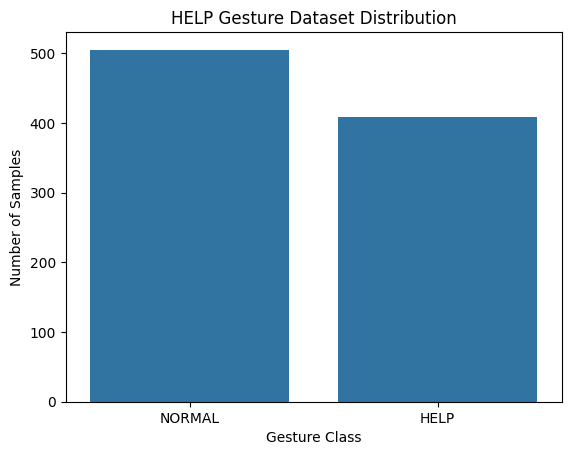

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("help_gesture.csv")

print("Dataset Shape:", df.shape)
print(df.head())

print("\nClass Distribution:")
print(df["label"].value_counts())

sns.countplot(data=df, x="label")

plt.title("HELP Gesture Dataset Distribution")
plt.xlabel("Gesture Class")
plt.ylabel("Number of Samples")
plt.show()

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

X = df.drop("label", axis=1)
y = df["label"]

encoder = LabelEncoder()
y = encoder.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 730
Testing samples: 183


In [5]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=300,
    max_depth=20,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

print("Model Training Completed!")

Model Training Completed!


Accuracy: 0.9617486338797814

Classification Report:
              precision    recall  f1-score   support

        HELP       0.99      0.93      0.96        82
      NORMAL       0.94      0.99      0.97       101

    accuracy                           0.96       183
   macro avg       0.97      0.96      0.96       183
weighted avg       0.96      0.96      0.96       183



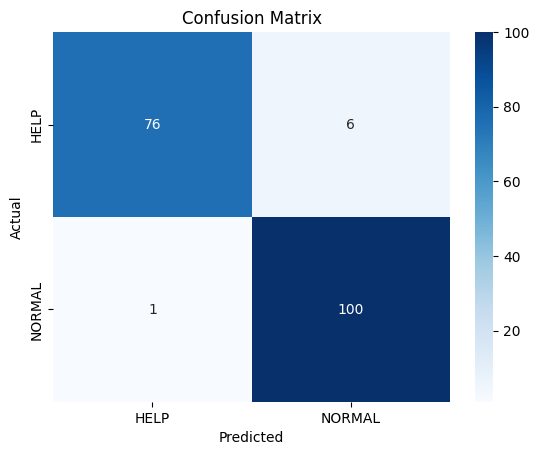

In [7]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=encoder.classes_
    )
)

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_,
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [8]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(
    {
        "model": model,
        "encoder": encoder
    },
    "models/help_gesture_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [11]:
files.download("models/help_gesture_model.pkl")

NameError: name 'files' is not defined